<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup, recordings and live mode](README.md)

# 01 · What does a longer Instant Answer shortlist add?

A unified search schema can hide differences in what providers return. DuckDuckGo's **Instant Answer API is an answer box and related-topic feed, not a general web-results page**. We will inspect two fixed technical topics, distinguish abstracts from related topics, and ask whether expanding a shortlist adds different URL hosts or merely more rows from the same host.

**Default: recorded public responses**, captured on **2026-11-14 at 09:59:17 UTC** for `Python (programming language)` and `Apache Arrow`. Exact response bytes, request URLs, UTC timestamps and SHA256 hashes are stored under `recordings/`. These are real responses, not synthetic fixtures. Replay still calls the real tagged worker through VGI; only its provider HTTP endpoint is redirected to an exact-match local server. Live mode makes the same four bounded public reads, with no fallback to recordings.

## Choose the local shortlist length

`TOP_N` is an integer from **1 to 12**, default **3**; the experiment uses **8**. It selects the first N rows **within each query** from an already materialized page of at most 50 rows. It does not change the requests or claim to retrieve the whole web.

`DATA_MODE` is **`"replay"`** or **`"live"`**. Live uses these same two fixed queries; timestamps, response hashes and counts update. An empty/non-JSON upstream response fails explicitly. Neither a SQL LIMIT nor the worker's DDG count argument limits network response bytes: DDG returns a complete answer payload, then the worker parses and slices it. Restart Kernel → Run All after editing.

In [1]:
TOP_N = 3  # Local prefix per query; experiment: 8
DATA_MODE = "replay"  # replay or live; never silently falls back

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from recorded_api import RecordedAPI

assert type(TOP_N) is int and 1 <= TOP_N <= 12
assert DATA_MODE in {"replay", "live"}
run_utc = datetime.now(UTC).isoformat()
manifest = json.loads(Path("recordings/manifest.json").read_text())
api = RecordedAPI(Path("recordings"), DATA_MODE, Path("artifacts"))
previous_endpoint = os.environ.get("VGI_SEARCH_DDG_BASE_URL")
os.environ["VGI_SEARCH_DDG_BASE_URL"] = api.url
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"DDG Instant Answer · {DATA_MODE} · response times shown above · URL hosts are not independent evidence",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.93))
    plt.show()


fixture_secret_directory = TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == [], "Notebook must start without SQL secrets"
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-search/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-search/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-search/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-search/notebooks/pyproject.toml.

## Fetch once, then work with local tables

The literal tagged Git command installs a cached worker; it does not depend on this repository's source. The small HTTP companion accepts only the recorded paths and complete query arguments, at most twice per query. It does not rewrite response bodies or supply substitutes. Live forwarding identifies this notebook with a User-Agent; version 0.4.0's direct HTTP client predates the source's identifying-header fix.

`web_search` is a table function with named arguments. `web_answer` is a scalar with positional arguments, and may return a whole abstract rather than one line. It returns NULL both for no answer and for provider failure; the separate HTTP audit below prevents a failure from being mistaken for a valid absence.

Each query has one search call and one answer call: **four provider reads** total. They are independent reads in live mode, not an atomic snapshot. Capture SELECTs below read only ordinary materialized tables, avoiding repeated remote calls by DataFrame conversion.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'search' (
 TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-search.git@v0.4.0 --constraints worker-constraints.txt vgi-search-worker'
);
CREATE TABLE topics AS SELECT * FROM (VALUES
 ('python','Python (programming language)'),('arrow','Apache Arrow')
) AS t(query_id,query_text);
CREATE TABLE raw_hits AS
SELECT 'python' AS query_id,* FROM search.web_search('Python (programming language)',provider := 'ddg',count := 50,page := 0)
UNION ALL
SELECT 'arrow' AS query_id,* FROM search.web_search('Apache Arrow',provider := 'ddg',count := 50,page := 0);
CREATE TABLE answers AS
SELECT query_id,search.web_answer(query_text,'ddg') AS answer FROM topics;
CREATE TABLE hits AS
SELECT *,extra->>'result_kind' AS result_kind,
 nullif(lower(regexp_extract(url,'^[a-zA-Z][a-zA-Z0-9+.-]*://([^/:?#]+)',1)),'') AS url_host
FROM raw_hits;
CREATE TABLE selected AS SELECT * FROM hits WHERE rank<={{TOP_N}};

,Count


In [4]:
audit = json.loads(Path("artifacts/request-audit.json").read_text())
assert len(audit) == 4 and all(r["status"] == 200 for r in audit)
assert sorted(r["query_id"] for r in audit) == ["arrow", "arrow", "python", "python"]
assert all(r["bytes"] > 0 for r in audit)
source_times = []
for entry in manifest["entries"]:
    rows = [r for r in audit if r["query_id"] == entry["query_id"]]
    source_times.append(
        {
            "query_id": entry["query_id"],
            "mode": DATA_MODE,
            "provider_reads": len(rows),
            "source_received_utc": entry["received_utc"]
            if DATA_MODE == "replay"
            else " / ".join(r["received_utc"] for r in rows),
            "bytes_served": sum(r["bytes"] for r in rows),
        }
    )
display(pd.DataFrame(source_times))
all_hits = con.execute("SELECT * FROM hits ORDER BY query_id,rank").df()
fingerprint = hashlib.sha256(all_hits.to_json(orient="records", date_format="iso").encode()).hexdigest()
assert not all_hits.duplicated(["query_id", "rank"]).any()
for query_id, rows in all_hits.groupby("query_id"):
    assert rows["rank"].tolist() == list(range(1, len(rows) + 1)) and len(rows) <= 50
    assert rows.source.eq("ddg").all() and rows.result_kind.isin(["abstract", "related_topic"]).all()
    assert rows.url_host.notna().all()
    payload = json.loads(Path(f"artifacts/{query_id}-1.json").read_text())
    expected = []
    if payload.get("AbstractText"):
        expected.append(("abstract", payload.get("AbstractURL") or None))
    for topic in payload.get("RelatedTopics") or []:
        for item in topic.get("Topics", []) if "Topics" in topic else [topic]:
            if item.get("Text") and item.get("FirstURL"):
                expected.append(("related_topic", item["FirstURL"]))
    assert list(zip(rows.result_kind, rows.url, strict=True)) == expected[:50]
prose(
    f"**{DATA_MODE.title()} mode** made **{len(audit)} successful provider reads**, serving **{sum(r['bytes'] for r in audit):,} response bytes** in this run. The local page contains **{len(all_hits)} normalized rows**. Run clock: `{run_utc}`; source capture/receive times are separate above. Page fingerprint: `{fingerprint}`. These byte counts include the separate answer reads; they are not a measure of web coverage."
)

,query_id,mode,provider_reads,source_received_utc,bytes_served
0,python,replay,2,2026-11-14T09:59:17.056394+00:00,29082
1,arrow,replay,2,2026-11-14T09:59:17.191103+00:00,10098


**Replay mode** made **4 successful provider reads**, serving **39,180 response bytes** in this run. The local page contains **26 normalized rows**. Run clock: `2026-11-14T11:05:31.116458+00:00`; source capture/receive times are separate above. Page fingerprint: `9080e04305707b9f2d46c49e502f9b7a85b40b7419f65b848233a0d63f23b3d7`. These byte counts include the separate answer reads; they are not a measure of web coverage.

## Preserve availability before making a shortlist

Count rows, distinct exact URLs, hosts and source metadata separately. Missing publication times and relevance scores remain **NULL**, not zero or today's date. Retrieval time does not say when a page was published. A host count describes the returned URLs; it does not identify independent authors or independent evidence.

The worker assigns rank from response order: abstract first, then related topics after flattening one group level. This is not a calibrated relevance score. Ranks are meaningful only within a query's returned page, not across these two topics.

In [5]:
%%sql coverage <<
SELECT t.query_id,t.query_text,
 (SELECT count(*) FROM hits h WHERE h.query_id=t.query_id) AS materialized_rows,
 count(s.rank) AS selected_rows,count(DISTINCT s.url) AS selected_exact_urls,
 count(DISTINCT s.url_host) AS selected_url_hosts,
 count(s.published) AS known_publication_times,count(s.score) AS known_scores,
 length(a.answer) AS answer_characters,
 CASE WHEN a.answer IS NULL THEN 'unavailable (absence or failure; inspect HTTP audit)' ELSE 'present' END AS answer_status
FROM topics t LEFT JOIN selected s USING(query_id) LEFT JOIN answers a USING(query_id)
GROUP BY t.query_id,t.query_text,a.answer ORDER BY t.query_id;

In [6]:
%%sql shortlist <<
SELECT query_id,rank,result_kind,left(title,65) AS title_prefix,url,url_host,
 published,score,length(snippet) AS snippet_characters
FROM selected ORDER BY query_id,rank;

,query_id,query_text,materialized_rows,selected_rows,selected_exact_urls,selected_url_hosts,known_publication_times,known_scores,answer_characters,answer_status
0,arrow,Apache Arrow,4,3,3,2,0,0,486,present
1,python,Python (programming language),22,3,3,2,0,0,927,present


,query_id,rank,result_kind,title_prefix,url,url_host,published,score,snippet_characters
0,arrow,1,abstract,Apache Arrow,https://en.wikipedia.org/wiki/Apache_Arrow,en.wikipedia.org,NaT,NaN,486
1,arrow,2,related_topic,Software frameworks,https://duckduckgo.com/c/Software_frameworks,duckduckgo.com,NaT,NaN,19
2,arrow,3,related_topic,Apache Software Foundation projects,https://duckduckgo.com/c/Apache_Software_Found...,duckduckgo.com,NaT,NaN,35
3,python,1,abstract,Python (programming language),https://en.wikipedia.org/wiki/Python_(programm...,en.wikipedia.org,NaT,NaN,927
4,python,2,related_topic,Python (programming language) Category,https://duckduckgo.com/c/Python_(programming_l...,duckduckgo.com,NaT,NaN,38
5,python,3,related_topic,Pydoc,https://duckduckgo.com/Pydoc,duckduckgo.com,NaT,NaN,87


The **top 3 per query** selects **6 rows** and **6 query–URL memberships**. All returned publication dates and scores are missing for this DDG mapping; **no freshness or confidence ranking can be computed** from them. The answer character counts describe returned text length, not correctness. Neither materialized page reached the 50-row cap; that still says nothing about the completeness of web coverage.

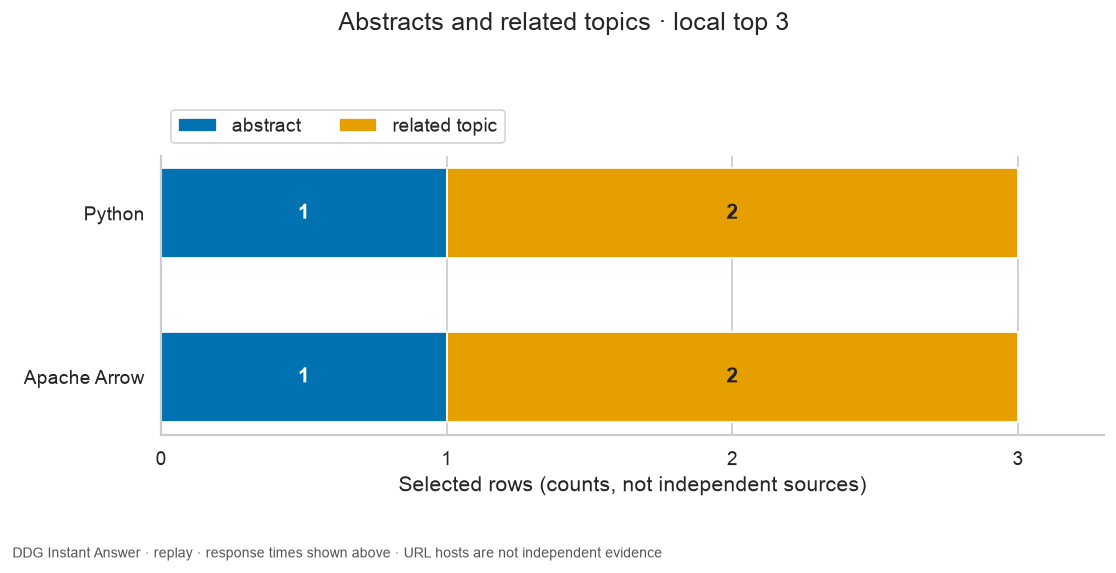

In [7]:
display(coverage)
display(shortlist)
assert (coverage.selected_rows == np.minimum(coverage.materialized_rows, TOP_N)).all()
assert (coverage.selected_url_hosts <= coverage.selected_exact_urls).all()
assert (coverage.selected_exact_urls <= coverage.selected_rows).all()
assert all_hits.published.isna().all() and all_hits.score.isna().all()
prose(
    f"The **top {TOP_N} per query** selects **{coverage.selected_rows.sum()} rows** and **{coverage.selected_exact_urls.sum()} query–URL memberships**. All returned publication dates and scores are missing for this DDG mapping; **no freshness or confidence ranking can be computed** from them. The answer character counts describe returned text length, not correctness. {'At least one materialized page reached the 50-row cap; it may be truncated.' if coverage.materialized_rows.ge(50).any() else 'Neither materialized page reached the 50-row cap; that still says nothing about the completeness of web coverage.'}"
)
kind_counts = con.execute(
    "SELECT query_id,result_kind,count(*) AS rows FROM selected GROUP BY query_id,result_kind ORDER BY query_id,result_kind"
).df()
order = ["arrow", "python"]
labels = {"arrow": "Apache Arrow", "python": "Python"}
colors = {"abstract": "#0072b2", "related_topic": "#e69f00"}
fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(order))
for kind in ["abstract", "related_topic"]:
    values = (
        kind_counts.loc[kind_counts.result_kind == kind]
        .set_index("query_id")["rows"]
        .reindex(order, fill_value=0)
        .to_numpy()
    )
    ax.barh(
        [labels[q] for q in order],
        values,
        left=left,
        label=kind.replace("_", " "),
        color=colors[kind],
        height=0.55,
    )
    for i, (v, start) in enumerate(zip(values, left, strict=True)):
        if v:
            ax.text(
                start + v / 2,
                i,
                str(v),
                ha="center",
                va="center",
                color="white" if kind == "abstract" else "#222222",
                fontweight="bold",
            )
    left += values
ax.set(xlabel="Selected rows (counts, not independent sources)", xlim=(0, max(1, TOP_N) + 0.3))
ax.set_xticks(range(TOP_N + 1))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2)
fig.suptitle(f"Abstracts and related topics · local top {TOP_N}")
finish(fig)

## Trace how the prefix grows

Build every local prefix from one through twelve without querying the provider again. Count distinct exact URLs and URL hosts at each cutoff. Exact URL deduplication does not merge aliases, redirects or pages with tracking parameters. A DuckDuckGo related-topic URL is a navigation link, not proof that we fetched or verified an independent source document.

The same colors identify each measure in both panels. Axes are fixed across the default and experiment; the vertical line marks the selected cutoff. A plateau means this materialized page adds no more rows for that cutoff, not that the topic has no more information on the web.

In [8]:
%%sql growth <<
SELECT t.query_id,n.cutoff,count(h.rank) AS rows,
 count(DISTINCT h.url) AS exact_urls,count(DISTINCT h.url_host) AS url_hosts
FROM topics t CROSS JOIN range(1,13) n(cutoff)
LEFT JOIN hits h ON h.query_id=t.query_id AND h.rank<=n.cutoff
GROUP BY t.query_id,n.cutoff ORDER BY t.query_id,n.cutoff;

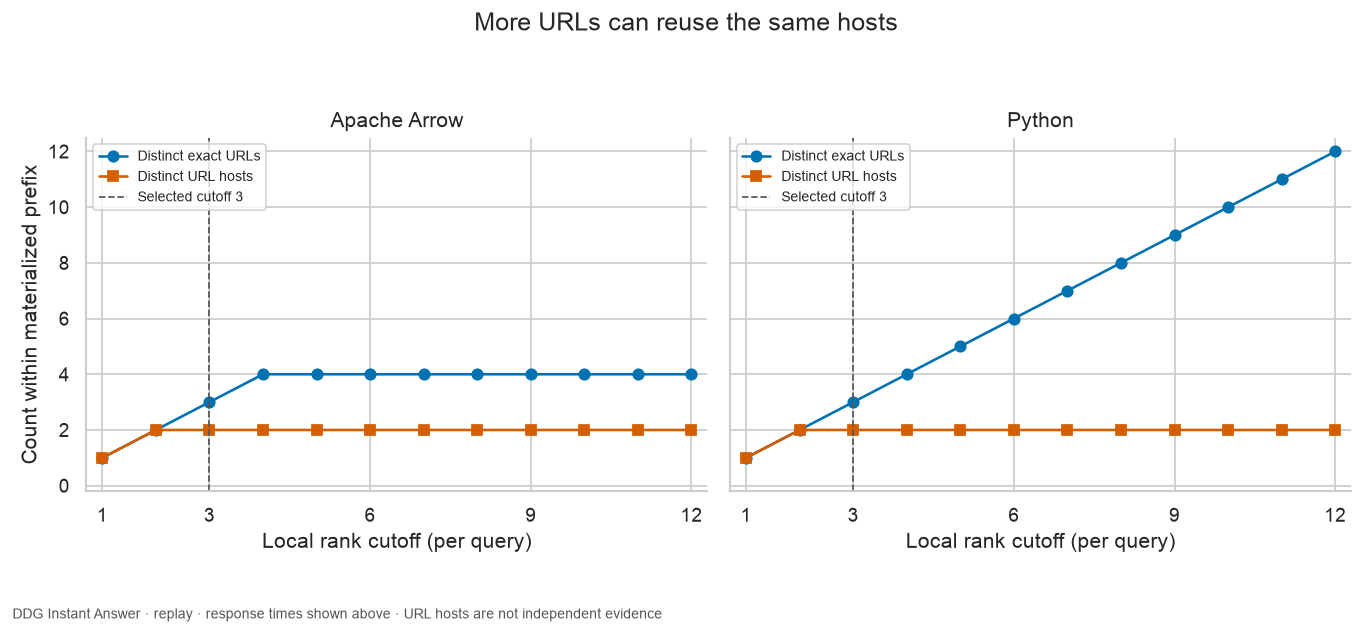

,query_id,url_host,rows
0,arrow,duckduckgo.com,2
1,arrow,en.wikipedia.org,1
2,python,duckduckgo.com,2
3,python,en.wikipedia.org,1


At the selected cutoff, **Apache Arrow** has **3 exact URLs across 2 hosts**; **Python (programming language)** has **3 exact URLs across 2 hosts**. These are URL-host concentrations, not independent-source counts. Before using any shortlist as evidence, inspect the actual documents and their relationship to the claim; this notebook does not fetch those pages.

6385

In [9]:
for _, g in growth.groupby("query_id"):
    for name in ["rows", "exact_urls", "url_hosts"]:
        assert np.all(np.diff(g[name]) >= 0)
    assert (g.url_hosts <= g.exact_urls).all() and (g.exact_urls <= g.rows).all()
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, query_id in zip(axes, ["arrow", "python"], strict=True):
    g = growth.loc[growth.query_id == query_id]
    ax.plot(g.cutoff, g.exact_urls, color="#0072b2", marker="o", label="Distinct exact URLs")
    ax.plot(g.cutoff, g.url_hosts, color="#d55e00", marker="s", label="Distinct URL hosts")
    ax.axvline(TOP_N, color="#555555", ls="--", lw=1, label=f"Selected cutoff {TOP_N}")
    ax.set(
        title=labels[query_id],
        xlabel="Local rank cutoff (per query)",
        xlim=(0.7, 12.3),
        ylim=(-0.2, 12.5),
        xticks=[1, 3, 6, 9, 12],
    )
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Count within materialized prefix")
fig.suptitle("More URLs can reuse the same hosts")
finish(fig)
hosts = con.execute(
    "SELECT query_id,url_host,count(*) AS rows FROM selected GROUP BY query_id,url_host ORDER BY query_id,rows DESC,url_host"
).df()
display(hosts)
prose(
    "At the selected cutoff, "
    + "; ".join(
        f"**{row.query_text}** has **{row.selected_exact_urls} exact URLs across {row.selected_url_hosts} hosts**"
        for row in coverage.itertuples()
    )
    + ". These are URL-host concentrations, not independent-source counts. Before using any shortlist as evidence, inspect the actual documents and their relationship to the claim; this notebook does not fetch those pages."
)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "top_n": TOP_N,
            "run_utc": run_utc,
            "page_fingerprint": fingerprint,
            "coverage": coverage.to_dict(orient="records"),
            "growth": growth.to_dict(orient="records"),
            "hosts": hosts.to_dict(orient="records"),
            "requests": audit,
        },
        indent=2,
    )
)

## Experiment: expand the local shortlist

Change only `TOP_N` from **3 to 8**, keeping `DATA_MODE="replay"`. Predict more selected related topics for a page that has them, but few additional URL hosts. Compare the selected table, result-kind bars and marked positions on the prefix curves. The page fingerprint, response hashes, complete growth curves and **four-request audit** must stay unchanged apart from replay-run timestamps. Restore **3** afterwards.

An answer, a related-topic URL, a publication date, a relevance score and a verified citation are different objects. This workflow preserves those distinctions. The result does not measure search recall, relevance, factual accuracy or provider quality. Other providers have different mappings, paging and score semantics; switching the provider requires a fresh interpretation, not just a renamed chart.

In [10]:
con.close()
fixture_secret_directory.cleanup()
api.close()
if previous_endpoint is None:
    os.environ.pop("VGI_SEARCH_DDG_BASE_URL", None)
else:
    os.environ["VGI_SEARCH_DDG_BASE_URL"] = previous_endpoint

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)